# - Master Kode Tugas NLP Trio Bertiga -

**Proyek:** Prediksi Peristiwa Geopolitik Global | Dampak terhadap Nilai Tukar USD/IDR.
**Hipotesis:** berita geopolitik global berpengaruh signifikan terhadap fluktuasi kurs USD/IDR.

Notebook ini adalah **master kode** gabungan seluruh kode yang dipakai pada **Tugas 1–3**. Disusun mengikuti **alur proses** (bisa dijalankan dari atas ke bawah), dengan **tag role** di tiap sesi.

### Tim
| Anggota | Role utama |
|---|---|
| **Mikail Achmad** (24/542370/PA/23026) | Akuisisi data kurs & temporal alignment, formulasi target, split, naive baseline, fusion & analisis error |
| **Widad Muhammad Rafi** (24/545635/PA/23190) | Scraping berita, align/merge, transformer embedding (FinBERT), studi ablasi |
| **Pratama Nanindra Aji** (24/533677/PA/22604) | Cleaning & filtering teks, fitur NLP dasar, static embedding, LDA, XGBoost |

### Cara pakai
1. Jalankan **Sesi 0 (Setup)** lebih dulu untuk mengatur path, import, dan flag `RUN_HEAVY`.
2. Tiap sesi diberi tag `[Nama]`. Isi/ubah **hanya sesi role**.
3. Sesi berat (scraping, FinBERT, unduh GloVe, LDA) default **membaca cache**, set `RUN_HEAVY = True` di Sesi 0 untuk menghitung ulang.
4. Sesi tim lain yang belum diisi akan memunculkan `NotImplementedError` by design (ada **kontrak input/output** di tiap placeholder sebagai panduan menambal).

## Peta Kontribusi (proses → role → status)

| # | Proses | Role | Status |
|---|---|---|---|
| 1.1 | Scraping Berita CNBC | Rafi | ⬜ placeholder |
| 1.2 | Akuisisi + Cleaning Kurs JISDOR | **Mikail** | ✅ terisi |
| 1.3 | Cleaning + Filtering + Preprocessing Teks | Aji | ✅ terisi |
| 1.4 | Temporal Alignment berita↔hari bursa | **Mikail** | ✅ terisi |
| 1.5 | Visualisasi Tren Kurs | **Mikail** | ✅ terisi |
| 2.1 | Formulasi Target (3-class + regresi) | **Mikail** | ✅ terisi |
| 2.2 | Split Kronologis Train/Val/Test | **Mikail** | ✅ terisi |
| 2.3 | Naive Baseline (Persistence/Majority) | **Mikail** | ✅ terisi |
| 2.4 | Fitur NLP Dasar (lexicon + TF-IDF/SVD) | Aji/Rafi | ⬜ placeholder |
| 2.5 | XGBoost TS-only / NLP-only / Gabungan | Aji | ✅ terisi |
| 3.1 | Static Embeddings (W2V/FastText/GloVe) | Aji | ✅ terisi |
| 3.2 | Topic Modeling LDA + t-SNE | Aji | ⬜ placeholder |
| 3.3 | Transformer Embedding FinBERT (Model C) | Rafi | ⬜ placeholder |
| 3.4 | Fusion Early + Late | **Mikail** | ✅ terisi |
| 3.5 | Studi Ablasi Model A / B / C | Rafi | ⬜ placeholder |
| 3.6 | Analisis Korelasi & Error | **Mikail** | ✅ terisi |

## 0. Setup & Konfigurasi  &nbsp;·&nbsp; `[Bersama]`

In [4]:
# Path & environment
import os, sys, json
from pathlib import Path

# REPO_ROOT = folder notebook ini (main.ipynb ada di root repo).
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

# Toggle langkah berat
# False = baca cache (cepat, tanpa GPU/unduhan). True = hitung ulang dari mentah.
RUN_HEAVY = False

# Folder standar
PATHS = {
    "processed": REPO_ROOT / "data" / "processed",
    "split":     REPO_ROOT / "data" / "split",          # <- split kanonik
    "features":  REPO_ROOT / "data" / "feature_extracted",
    "results":   REPO_ROOT / "results",
}

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("REPO_ROOT :", REPO_ROOT)
print("RUN_HEAVY :", RUN_HEAVY)

REPO_ROOT : d:\Kuliah\Tugas dan Projek\Pemrosesan Bahasa Alami\repo\nlp-trio-bertiga
RUN_HEAVY : False


In [5]:
# Helper bersama
def load_json(name: str) -> dict:
    """Baca file JSON dari folder results/."""
    with open(PATHS["results"] / name, "r", encoding="utf-8") as f:
        return json.load(f)

def show_results(name: str, splits=("val", "test")):
    """Ringkas metrik klasifikasi+regresi dari file *_results.json."""
    d = load_json(name)
    rows = []
    for s in splits:
        clf = d.get("classification", {}).get(s, {})
        reg = d.get("regression", {}).get(s, {})
        rows.append({
            "split": s,
            "accuracy": clf.get("accuracy"),
            "macro_f1": clf.get("macro_f1"),
            "rmse": reg.get("rmse"),
            "skill_vs_naive": reg.get("skill_vs_naive"),
            "directional_hit": reg.get("directional_hit"),
        })
    return pd.DataFrame(rows)

def show_png(name: str, width=560):
    """Tampilkan gambar hasil dari results/ (jika ada)."""
    from IPython.display import Image, display
    p = PATHS["results"] / name
    display(Image(filename=str(p), width=width)) if p.exists() else print("(belum ada)", p.name)

---
# TUGAS 1 — Akuisisi Data & Preprocessing Strategis

### 1.1 Scraping Berita CNBC &nbsp;·&nbsp; `[Rafi]`

In [ ]:
# TODO [Rafi] — Scraping berita CNBC (Google News RSS discovery → CNBC HTTP → parse)
# INPUT  : rentang tanggal + keyword geopolitik/ekonomi/kurs
# PROSES : Google News RSS discovery -> dedup URL CNBC -> requests + BeautifulSoup
#          -> ekstrak body (ArticleBody) + metadata JSON-LD (judul, tanggal, penulis)
# OUTPUT : data/raw/news/<...>.csv  (kolom: url, title, published_at, author, body)
# Acuan  : src/scrapping/news_scraper.py, src/scrapping/Scrapping.ipynb
# Catatan: bungkus eksekusi jaringan dengan `if RUN_HEAVY:`; kalau tidak, muat CSV cache.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
raise NotImplementedError("Sesi Rafi belum diisi.")

### 1.2 Akuisisi + Cleaning Kurs JISDOR &nbsp;·&nbsp; `[Mikail]`

Sumber mutlak **Bank Indonesia (JISDOR)**, periode 2021-09 → 2026-08. Pipeline:
baca XLSX/CSV mentah → standarisasi kolom tanggal → validasi (duplikat, tanggal
rusak, kurs non-positif) → urut kronologis. Modul: `src/jisdor/preprocess_jisdor.py`.

In [6]:
from src.jisdor.preprocess_jisdor import load_jisdor_csv, preprocess_jisdor

JISDOR_CLEAN = PATHS["processed"] / "jisdor_clean.csv"

if RUN_HEAVY:
    # Jalankan ulang cleaning dari sumber mentah (sesuaikan path XLSX bila perlu).
    raw = load_jisdor_csv(PATHS["processed"].parent / "raw" / "Informasi_Kurs_Jisdor.xlsx")
    jisdor = preprocess_jisdor(raw)
    jisdor.to_csv(JISDOR_CLEAN, index=False, date_format="%Y-%m-%d")
else:
    jisdor = pd.read_csv(JISDOR_CLEAN, parse_dates=["tanggal"])

print(f"Kurs JISDOR bersih: {len(jisdor)} hari | {jisdor['tanggal'].min().date()} → {jisdor['tanggal'].max().date()}")
jisdor.head()

Kurs JISDOR bersih: 1202 hari | 2021-09-01 → 2026-09-01


,tanggal,kurs_jisdor
0,2021-09-01,14284
1,2021-09-02,14281
2,2021-09-03,14261
3,2021-09-06,14239
4,2021-09-07,14195


### 1.3 Cleaning + Filtering + Preprocessing Teks &nbsp;·&nbsp; `[Aji]`

Proses data preparation melalui tahap cleaning, filtering, dan preprocessing.
1. **Cleaning:** teks (hapus tag, entitas, dan karakter yang tidak diperlukan).
2. **Filtering:** validasi kolom wajib dan pilih berita yang relevan berdasarkan kata kunci geopolitik.
3. **Preprocessing:** hasilkan `text_clean_light` untuk pemrosesan umum dan `text_clean_classical` beserta token untuk analisis klasik.

Modul: 
- `src/cleaning/text_cleaning.py`
- `src/filtering/text_filtering.py`
- `src/preprocessing/text_preprocessing.py`

In [ ]:

# TODO [Aji] — Cleaning HTML → filtering relevansi geopolitik → preprocessing (light & classical)
# INPUT  : data/raw/news/*.csv (hasil scraping 1.1)
# PROSES : cleaning.clean_text -> filter_news (field wajib + keyword geopolitik)
#          -> preprocess_documents (text_clean_light & text_clean_classical/tokens)
# OUTPUT : data/processed/news_preprocessed.csv
# Acuan  : src/main.ipynb, src/filtering/text_filtering.py,
#          src/preprocessing/text_preprocessing.py, src/cleaning/Cleaning_article.ipynb
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.cleaning.text_cleaning import clean_text
from src.filtering.text_filtering import filter_news
from src.preprocessing.text_preprocessing import preprocess_documents

raw_dir = REPO_ROOT / "data" / "raw" / "news"
output_path = PATHS["processed"] / "news_preprocessed.csv"
PATHS["processed"].mkdir(parents=True, exist_ok=True)

raw_files = sorted(raw_dir.glob("*.csv"))
if not raw_files:
    raise FileNotFoundError(f"Tidak ditemukan CSV berita di {raw_dir}")

news = pd.concat(
    [pd.read_csv(path) for path in raw_files],
    ignore_index=True
)

required_columns = {"url", "title", "published_at", "body"}
missing = required_columns - set(news.columns)
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing)}")

news = news.drop_duplicates(subset="url").copy()

def clean_value(value):
    return clean_text(value) if pd.notna(value) else ""

news["title"] = news["title"].map(clean_value)
news["body"] = news["body"].map(clean_value)

news = filter_news(news)
if news is None or news.empty:
    raise ValueError("Tidak ada berita yang lolos filtering.")

news = preprocess_documents(news)
if news is None:
    raise ValueError("preprocess_documents harus mengembalikan DataFrame.")

news.to_csv(output_path, index=False)
print(f"Berhasil menyimpan {len(news)} berita ke {output_path}")
news.head()

### 1.4 Temporal Alignment berita ↔ hari bursa &nbsp;·&nbsp; `[Mikail]`

Pasar beroperasi hari kerja; berita 24/7. Aturan: berita yang terbit **setelah jam
tutup pasar** didorong ke hari berikutnya, lalu **maju ke trading day** terdekat
(otomatis melompati akhir pekan & libur nasional via library `holidays`). Fungsi
inti di-*inline* di bawah agar mudah dijelaskan saat evaluasi.

In [7]:
from datetime import time
import holidays

MARKET_CLOSE_TIME = time(16, 0)                       # asumsi jam tutup pasar
ID_HOLIDAYS = holidays.Indonesia(years=range(2021, 2027))

def is_trading_day(date) -> bool:
    """True jika tanggal adalah hari bursa (bukan akhir pekan / libur nasional)."""
    d = pd.Timestamp(date).normalize()
    return d.weekday() < 5 and d.date() not in ID_HOLIDAYS

def get_effective_trading_date(news_datetime):
    """Petakan timestamp berita ke trading day kurs yang relevan."""
    ts = pd.Timestamp(news_datetime)
    d = ts.normalize()
    if is_trading_day(d) and ts.time() >= MARKET_CLOSE_TIME:   # setelah tutup -> besok
        d += pd.Timedelta(days=1)
    while not is_trading_day(d):                               # maju ke trading day
        d += pd.Timedelta(days=1)
    return d

# Demo aturan dengan contoh timestamp:
for ts in ["2023-01-16 09:00", "2023-01-16 17:30", "2022-12-25 08:00"]:
    print(f"  {ts:<20} → {get_effective_trading_date(ts).date()}")

# Integrasi ke data berita (jalankan setelah 1.3 menghasilkan news_preprocessed.csv):
#   news["trading_date"] = news["published_at"].apply(get_effective_trading_date)

  2023-01-16 09:00     → 2023-01-16
  2023-01-16 17:30     → 2023-01-17
  2022-12-25 08:00     → 2022-12-26


### 1.5 Visualisasi Tren Kurs &nbsp;·&nbsp; `[Mikail]`

Tren harian kurs JISDOR sepanjang periode penelitian. Modul lengkap (tahunan,
dengan anotasi peristiwa, output PNG/HTML plotly): `src/jisdor/visualize_jisdor.py`.

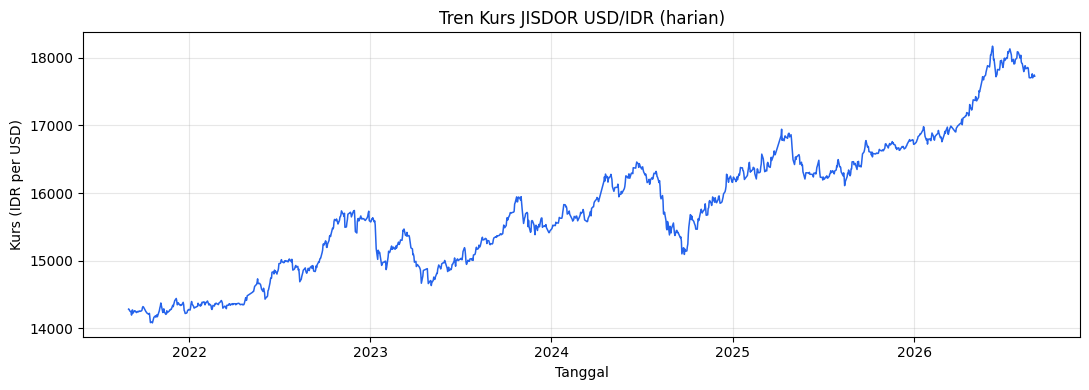

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(jisdor["tanggal"], jisdor["kurs_jisdor"], lw=1.1, color="#2563eb")
ax.set_title("Tren Kurs JISDOR USD/IDR (harian)")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Kurs (IDR per USD)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Versi lengkap:
# from src.jisdor.visualize_jisdor import plot_trend_harian, plot_trend_tahunan
# plot_trend_harian()

---
# TUGAS 2 — Baseline & Formulasi Target

### 2.1 Formulasi Target (3-class + regresi) &nbsp;·&nbsp; `[Mikail]`

Dua target dari sumber sama, keduanya untuk **besok** (shift −1):
- **Klasifikasi 3-class** `target`: NAIK / STABIL / TURUN, threshold ±0.1% pada
  `pct_change` (kelas STABIL mencegah ~30% hari ter-drop di dekat nol).
- **Regresi** `kurs_besok`: level kurs hari t+1.

Modul: `src/jisdor/target_formulation.py`. Fungsi inti di-*inline*:

In [9]:
THRESHOLD_PCT = 0.1

def label_direction(pct_change, threshold=THRESHOLD_PCT):
    """Label arah: NAIK / TURUN / STABIL (None bila NaN)."""
    if pd.isna(pct_change):
        return None
    if pct_change > threshold:
        return "NAIK"
    if pct_change < -threshold:
        return "TURUN"
    return "STABIL"

def build_target(df, threshold=THRESHOLD_PCT):
    """Tambah pct_change, target 3-class (besok), dan kurs_besok (regresi)."""
    df = df.copy()
    df["pct_change"] = df["kurs_jisdor"].pct_change() * 100
    df["target"] = df["pct_change"].apply(lambda x: label_direction(x, threshold)).shift(-1)
    df["kurs_besok"] = df["kurs_jisdor"].shift(-1)
    return df.dropna(subset=["target", "kurs_besok"]).reset_index(drop=True)

jisdor_target = build_target(jisdor.sort_values("tanggal").reset_index(drop=True))
print(f"{len(jisdor_target)} baris berlabel. Distribusi target:")
print(jisdor_target["target"].value_counts())
jisdor_target.head()

1201 baris berlabel. Distribusi target:
target
NAIK      477
STABIL    362
TURUN     362
Name: count, dtype: int64


,tanggal,kurs_jisdor,pct_change,target,kurs_besok
0,2021-09-01,14284,NaN,STABIL,14281.0
1,2021-09-02,14281,-0.021003,TURUN,14261.0
2,2021-09-03,14261,-0.140046,TURUN,14239.0
3,2021-09-06,14239,-0.154267,TURUN,14195.0
4,2021-09-07,14195,-0.309010,NAIK,14266.0


### 2.2 Split Kronologis Train/Val/Test &nbsp;·&nbsp; `[Mikail]`

Split **kronologis 80/10/10** (tanpa shuffle, menjaga urutan waktu & mencegah
kebocoran). Membawa kedua target sekaligus. Modul: `src/jisdor/split_dataset.py`.

In [10]:
from src.jisdor.split_dataset import chronological_split

train, val, test = chronological_split(jisdor_target)
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(d):4d} baris | {d['tanggal'].min().date()} → {d['tanggal'].max().date()}")
# Catatan: file resmi sudah tersimpan di data/split/{train,val,test}.csv

train:  959 baris | 2021-09-01 → 2025-08-26
val  :  119 baris | 2025-08-28 → 2026-02-19
test :  121 baris | 2026-02-23 → 2026-08-31


### 2.3 Naive Baseline &nbsp;·&nbsp; `[Mikail]`

Dua acuan minimal yang wajib dikalahkan model:
- **Persistence of Direction** — arah besok = arah hari ini.
- **Majority-Class** — selalu kelas mayoritas train.
- **Random Walk** (regresi) — kurs besok = kurs hari ini.

Modul lengkap (+ metrik & JSON): `src/models/naive_baseline.py`,
`src/models/naive_baseline_regression.py`. Fungsi inti di-*inline*:

In [11]:
from sklearn.metrics import accuracy_score, f1_score

def predict_persistence(targets: pd.Series):
    preds = targets.shift(1).values.copy()
    preds[0] = targets.mode().iloc[0]          # fallback baris pertama
    return preds

def predict_majority(targets_train: pd.Series, n: int):
    return np.full(n, targets_train.mode().iloc[0])

# Evaluasi pada split test (klasifikasi)
y_test = test["target"].reset_index(drop=True)
pred_pers = predict_persistence(y_test)
pred_maj  = predict_majority(train["target"], len(y_test))
for name, pred in [("Persistence", pred_pers), ("Majority", pred_maj)]:
    acc = accuracy_score(y_test, pred)
    f1  = f1_score(y_test, pred, average="macro")
    print(f"{name:12s}: acc={acc:.4f}  macro_f1={f1:.4f}")

# Regresi (random walk): kurs_besok_hat = kurs_jisdor hari ini
rmse_rw = float(np.sqrt(np.mean((test["kurs_besok"] - test["kurs_jisdor"])**2)))
print(f"Random Walk  : RMSE={rmse_rw:.2f}")

Persistence : acc=0.3802  macro_f1=0.3637
Majority    : acc=0.4463  macro_f1=0.2057
Random Walk  : RMSE=57.47


### 2.4 Fitur NLP Dasar (lexicon + TF-IDF/SVD) &nbsp;·&nbsp; `[Aji/Rafi]`

In [ ]:
# TODO [Aji/Rafi] — Ekstraksi fitur leksikon (VADER + Loughran-McDonald) & TF-IDF→SVD(50)
# INPUT  : data/processed/news_preprocessed.csv + data/split/{train,val,test}.csv
# PROSES : agregasi harian sentimen VADER & LM; TF-IDF (fit train) -> TruncatedSVD(50)
# OUTPUT : data/feature_extracted/model_dataset.csv
#          (kolom: ret_lag1..3, ret_std5, vader_*, lm_*, no_news, tfidf_svd_1..50, split, target, kurs_besok)
# Acuan  : src/03_feature_extraction.ipynb, src/03a_feature_extraction.ipynb
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
# raise NotImplementedError("Sesi Aji/Rafi belum diisi.")

### 2.5 XGBoost TS-only / NLP-only / Gabungan &nbsp;·&nbsp; `[Aji]`

Pipeline XGBoost untuk tiga skenario:
1. **TS-only**: hanya fitur time series (kurs, lag, moving average, dll).
2. **NLP-only**: hanya fitur NLP (lexicon, TF-IDF, SVD, dll).
3. **Gabungan**: gabungan fitur TS + NLP.

Modul: `src/models/xgb_ts_only.py`, `src/models/xgb_nlp_only.py`, `src/models/xgb_combined.py`.

In [ ]:

# TODO [Aji] — Baseline XGBoost: Model A (TS), NLP-only, dan Gabungan TS+NLP
# INPUT  : data/feature_extracted/model_dataset.csv
# PROSES : XGBoost klasifikasi (3-class) + regresi (delta->level), early_stopping pakai val
# OUTPUT : results/05_ts_only_*, results/06_nlp_only_*, results/04_gabungan_*
# Acuan  : src/models/xgb_ts_only.py, src/models/xgb_nlp_only.py, src/04_modeling.ipynb
# Tampilkan ringkasan dengan helper: show_results("05_ts_only_results.json") dsb.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.xgb_ts_only import main as run_ts_only
from src.models.xgb_nlp_only import main as run_nlp_only
from src.models.xgb_combined import main as run_combined

if RUN_HEAVY:

    run_ts_only(["--output-prefix", "04_ts_only"])
    run_nlp_only(["--output-prefix", "05_nlp_only"])
    run_combined(["--output-prefix", "06_gabungan"])

print("Baseline XGBoost — TS-only (Model A)")
display(show_results("04_ts_only_results.json"))

print("Baseline XGBoost — NLP-only")
display(show_results("05_nlp_only_results.json"))

print("Baseline XGBoost — Gabungan TS + NLP")
display(show_results("06_gabungan_results.json"))

---
# TUGAS 3 — Fitur Lanjut & Integrasi Multimodal

### 3.1 Static Embeddings (Word2Vec / FastText / GloVe) &nbsp;·&nbsp; `[Aji]`

Embedding statis/non-contextual menggunakan model pre-trained (Word2Vec, FastText, GloVe) untuk representasi kata. Modul: `src/embeddings/static_embeddings.py`.

In [ ]:
# TODO [Aji] — Static embedding NLP-only: Word2Vec, FastText, GloVe pretrained
# INPUT  : artikel train + split
# PROSES : fit Word2Vec/FastText di train; GloVe pretrained (unduh ~822MB bila RUN_HEAVY)
#          -> rata-rata vektor per dokumen -> fitur harian -> XGBoost NLP-only
# OUTPUT : results/07_word2vec_*, results/08_fasttext_*, results/09_glove_*
# Acuan  : src/models/static_embeddings/{word2vec,fasttext,glove}_nlp_only.py
#          notebook/static_embeddings_experiment.ipynb
# Catatan: bungkus unduhan/training GloVe & Word2Vec dengan `if RUN_HEAVY:`.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.static_embeddings.word2vec_nlp_only import main as run_word2vec
from src.models.static_embeddings.fasttext_nlp_only import main as run_fasttext
from src.models.static_embeddings.glove_nlp_only import main as run_glove

if RUN_HEAVY:
    run_word2vec(["--output-prefix", "07_word2vec"])
    run_fasttext(["--output-prefix", "08_fasttext"])
    run_glove(["--output-prefix", "09_glove"])
    
print("Static Embedding — Word2Vec NLP-only")
display(show_results("07_word2vec_results.json"))

print("Static Embedding — FastText NLP-only")
display(show_results("08_fasttext_results.json"))

print("Static Embedding — GloVe NLP-only")
display(show_results("09_glove_results.json"))

### 3.2 Topic Modeling LDA + Visualisasi t-SNE &nbsp;·&nbsp; `[Aji]`

Permodelan topik LDA untuk mengekstraksi tema dari korpus berita, diikuti dengan visualisasi t-SNE untuk representasi 2D. Modul: `src/models/lda_nlp_only.py`, `src/models/t_sne.py`.

In [ ]:
# TODO [Aji] — LDA tema geopolitik (8 topik) + t-SNE embedding ruang topik
# INPUT  : artikel preprocessed (classical tokens)
# PROSES : LDA (sklearn) 8 topik -> distribusi topik per artikel -> agregasi harian
#          -> fitur harian untuk XGBoost; t-SNE untuk visualisasi hari volatil vs tenang
# OUTPUT : results/10_lda_topics_*, data/feature_extracted/10_lda_topics_daily_features.csv
# Acuan  : src/models/lda_nlp_only.py, notebook/lda_geopolitical_topics.ipynb
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.lda_nlp_only import main as run_lda
from src.models.t_sne import main as run_tsne

run_lda(["--output-prefix", "10_lda_topics"])
run_tsne(["--input-file", "10_lda_topics_distributions.csv", "--output-file", "10_lda_topics_tsne.csv"])

print("LDA Topics — Geopolitical Topics")
display(show_results("10_lda_topics_results.json"))

print("t-SNE Visualization — LDA Topic Distributions")
show_png("10_lda_topics_tsne.png", width=640)

### 3.3 Transformer Embedding FinBERT (Model C) &nbsp;·&nbsp; `[Rafi]`

In [ ]:
# TODO [Rafi] — Embedding kontekstual FinBERT (768-d) -> PCA(50) -> fitur harian Model C
# INPUT  : artikel (text_clean_light) + split
# PROSES : FinBERT (ProsusAI/finbert) inference per artikel -> agregasi harian
#          -> PCA fit di train ke 50 komponen (no leakage) -> gabung kurs+lag
# OUTPUT : data/feature_extracted/model_dataset_transformer.csv,
#          embeddings_finbert_daily.csv
# Acuan  : src/03b_transformer_embedding.ipynb
# Catatan: butuh transformers+torch (+GPU). Bungkus inference dengan `if RUN_HEAVY:`,
#          selain itu muat embeddings_finbert_daily.csv dari cache.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
raise NotImplementedError("Sesi Rafi belum diisi.")

### 3.4 Fusion Early + Late &nbsp;·&nbsp; `[Mikail]`

Dua strategi integrasi multimodal TS + teks:
- **Early fusion** — concat fitur TS + teks → satu XGBoost (`src/models/fusion_early.py`).
- **Late fusion** — sub-model TS & teks terpisah, gabung probabilitas/logit
  dengan bobot dioptimasi di val (`src/models/fusion_late.py`).

Parametrik `--text-group` (basic=Model B, embedding=Model C, both=Model C+) agar
ablasi apple-to-apple. Default membaca hasil cache; set `RUN_HEAVY=True` untuk melatih ulang.

Early fusion (basic / Model B)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.4068,0.4009,55.6733,0.0060,0.5424
1,test,0.3017,0.2938,50.8200,0.0059,0.5978


Late fusion (basic / Model B)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3672,0.3597,55.4317,0.0103,0.5367
1,test,0.3687,0.3618,51.2912,-0.0033,0.5363


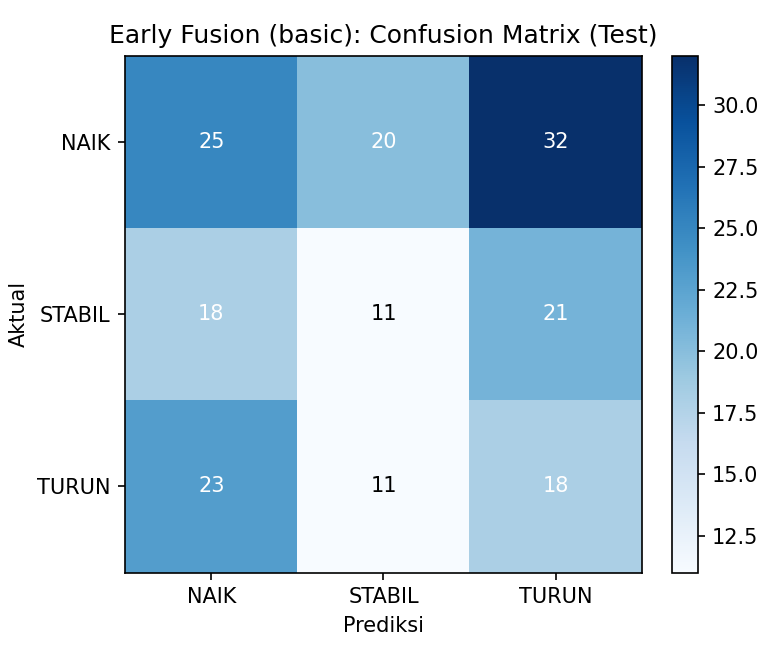

In [12]:
if RUN_HEAVY:
    from src.models.fusion_early import main as run_early
    from src.models.fusion_late import main as run_late
    run_early(["--text-group", "basic", "--output-prefix", "10_fusion_early_basic"])
    run_late(["--text-group", "basic", "--output-prefix", "11_fusion_late_basic"])

print("Early fusion (basic / Model B)")
display(show_results("10_fusion_early_basic_results.json"))
print("Late fusion (basic / Model B)")
display(show_results("11_fusion_late_basic_results.json"))
show_png("10_fusion_early_basic_confusion_matrix.png")

### 3.5 Studi Ablasi Model A / B / C &nbsp;·&nbsp; `[Rafi]`

In [ ]:
# TODO [Rafi] — Studi ablasi sistematis Model A (TS) vs B (TS+NLP dasar) vs C (TS+transformer)
# INPUT  : model_dataset.csv + model_dataset_transformer.csv
# PROSES : latih 4 varian dengan kode & hyperparameter identik; bandingkan macro-F1 & RMSE
# OUTPUT : results/04b_ablasi_* (results.json, comparison.csv, grafik)
# Acuan  : src/04b_ablation_study.ipynb
# Tampilkan: pd.read_csv(PATHS["results"]/"04b_ablasi_comparison.csv")
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
raise NotImplementedError("Sesi Rafi belum diisi.")

### 3.6 Analisis Korelasi & Error &nbsp;·&nbsp; `[Mikail]`

Mengidentifikasi **tanggal** di mana fitur NLP membantu menghindari sinyal palsu
pasar vs tanggal di mana teks justru menambah noise — membandingkan prediksi TS-only
vs fusion, dengan uji McNemar. Modul: `src/models/error_correlation.py`.

Ringkasan analisis error (early fusion vs TS-only):
{
  "baseline": "XGBoost TS-only",
  "candidate": "Early Fusion (basic)",
  "split": "test",
  "n_dates": 179,
  "classification": {
    "nlp_helped": 11,
    "nlp_hurt": 23,
    "both_correct": 43,
    "both_wrong": 102,
    "net_help": -12,
    "mcnemar": {
      "p_value": 0.0576,
      "n_discordant": 34,
      "favored": "baseline (NLP merusak)"
    }
  },
  "regression": {
    "mae_base": 38.4611,
    "mae_cand": 37.853,
    "dir_hit_base": 0.5028,
    "dir_hit_cand": 0.5978,
    "error_correlation": 0.9943,
    "dates_cand_closer": 105,
    "dates_base_closer": 74
  },
  "nlp_signal_vs_direction_corr": {
    "vader_title_mean": -0.0099,
    "vader_body_mean": -0.0375,
    "vader_neg_share": 0.0707,
    "lm_negative_mean": 0.0861,
    "lm_positive_mean": 0.0651,
    "lm_net_mean": -0.0569
  }
}


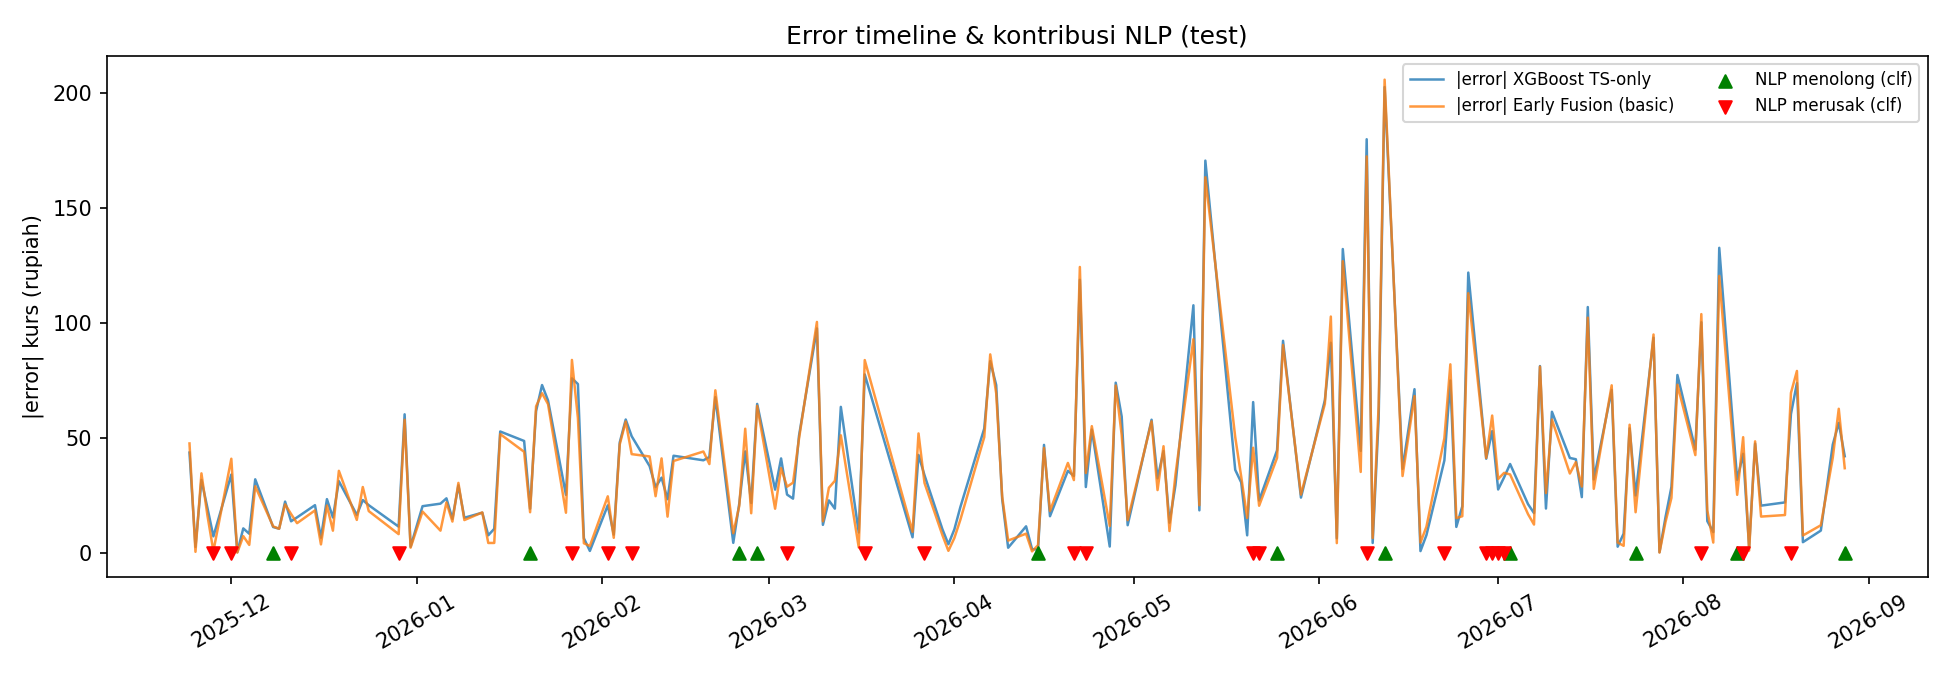

In [13]:
if RUN_HEAVY:
    from src.models.error_correlation import main as run_errcorr
    run_errcorr(["--fusion", "early", "--output-prefix", "12_errcorr_early_basic"])

errcorr = load_json("12_errcorr_early_basic_summary.json")
print("Ringkasan analisis error (early fusion vs TS-only):")
print(json.dumps(errcorr, indent=2, ensure_ascii=False))
show_png("12_errcorr_early_basic_error_timeline.png", width=760)

---
## Lampiran Ringkasan Hasil Semua Eksperimen
---

In [14]:
# Rangkum metrik test dari semua *_results.json yang tersedia di results/.
import glob
rows = []
for p in sorted(glob.glob(str(PATHS["results"] / "*_results.json"))):
    try:
        d = json.load(open(p, encoding="utf-8"))
    except Exception:
        continue
    t = d.get("classification", {}).get("test", {})
    r = d.get("regression", {}).get("test", {})
    rows.append({
        "file": Path(p).name,
        "model": d.get("model", "?"),
        "test_macro_f1": t.get("macro_f1"),
        "test_rmse": r.get("rmse"),
        "skill_vs_naive": r.get("skill_vs_naive"),
    })
summary = pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False, na_position="last")
summary.reset_index(drop=True)

,file,model,test_macro_f1,test_rmse,skill_vs_naive
0,05_ts_only_results.json,XGBoost TS-only (tanpa NLP),0.3626,50.9977,0.0025
1,11_fusion_late_basic_results.json,Late Fusion (basic),0.3618,51.2912,-0.0033
2,09_glove_results.json,XGBoost GloVe NLP-only (tanpa fitur time-series),0.3357,51.0882,0.0007
3,08_fasttext_results.json,XGBoost FastText NLP-only (tanpa fitur time-se...,0.3108,50.9107,0.0042
4,07_word2vec_results.json,XGBoost Word2Vec NLP-only (tanpa fitur time-se...,0.2964,50.7835,0.0066
5,07_word2vec_smoke_results.json,XGBoost Word2Vec NLP-only (tanpa fitur time-se...,0.2962,51.1409,-0.0003
6,07_word2vec_validation_results.json,XGBoost Word2Vec NLP-only (tanpa fitur time-se...,0.2962,51.1409,-0.0003
7,04_all_results.json,XGBoost Gabungan (TS+NLP),0.2938,50.8200,0.0059
8,10_fusion_early_basic_results.json,Early Fusion (basic),0.2938,50.8200,0.0059
9,06_nlp_only_results.json,XGBoost NLP-only (tanpa kurs),0.2856,50.7325,0.0076
